# A visual for computing the reflection coefficients


In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
from plog import Log

In [11]:
sigma = np.array([0.5, 0.1, 1])
lg = Log.standard(np.log10(sigma), [10, 20], 'conductivity')
lg.depth_bot[-1] = 30

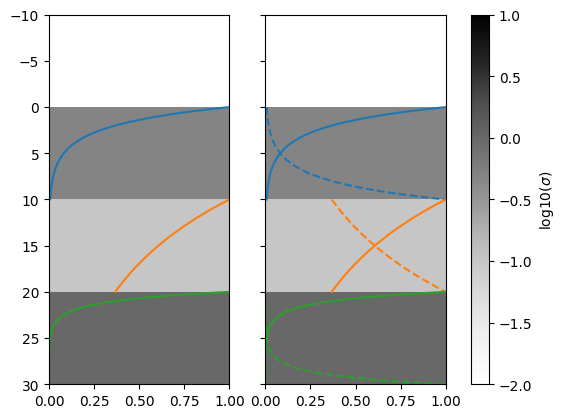

In [22]:
z = np.linspace(0, 10, 101)

A = 1.
B = 0.1

fig,axs = plt.subplots(1,2, sharey=True)
lg.plot(axs[0], x_offset=0.5, cmap='Greys', vmin=-2, vmax=1)
ax,pcm = lg.plot(axs[1], x_offset=0.5, cmap='Greys', cbar=True, vmin=-2, vmax=1)
for i,sgm in enumerate(sigma):
    y_dn = np.exp(-sgm*z)#*A
    y_up = np.exp(sgm*(z-10))#*B
    axs[0].plot(y_dn, z+i*10, f'C{i}')
    axs[1].plot(y_dn, z+i*10, f'C{i}')

    # axs[0].plot(y_up, z+i*10, f'C{i}--')
    axs[1].plot(y_up, z+i*10, f'C{i}--')

    A = y_dn.min()
    B *= np.exp(sgm*10)

# plt.xscale('log');plt.xlim(1e-5, 1)
plt.ylim(30,-10)
axs[0].set_xlim(0,1)
plt.colorbar(pcm, ax=axs, label='log10($\sigma$)')

Text(0.5, 0, 'normalized amplitude')

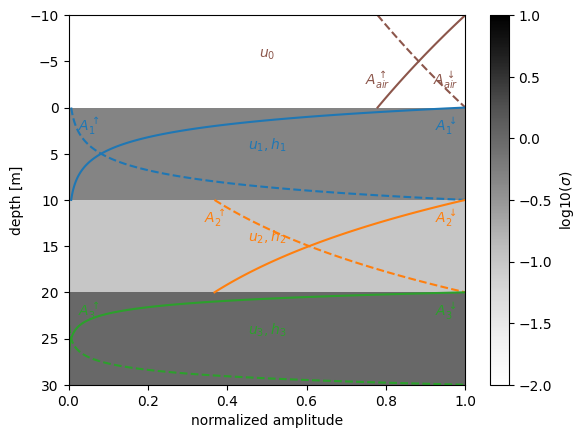

In [71]:
z = np.linspace(0, 10, 101)


fig,axs = plt.subplots(1,1, sharey=True); axs = [axs]
ax,pcm = lg.plot(axs[0], x_offset=0.5, cmap='Greys', vmin=-2, vmax=1)

i=-1
sgm=2.5e-2
y_dn = np.exp(-sgm*z)#*A
y_up = np.exp(sgm*(z-10))#*B
axs[0].plot(y_dn, z+i*10, f'C5')
axs[0].plot(y_up, z+i*10, f'C5--')
axs[0].annotate('$u_0$', (0.5, 5+i*10), ha='center', va='bottom', color=f'C5')

uparrow, dnarrow = '\\uparrow', '\\downarrow'
axs[0].annotate('$A_{{air}}^{{{:}}}$'.format(uparrow), (y_dn.min(), -3), ha='center', va='center', color=f'C5')
axs[0].annotate('$A_{{air}}^{{{:}}}$'.format(dnarrow), (0.95, -3), ha='center', va='center', color=f'C5')

for i,sgm in enumerate(sigma):
    y_dn = np.exp(-sgm*z)#*A
    y_up = np.exp(sgm*(z-10))#*B
    axs[0].plot(y_dn, z+i*10, f'C{i}')
    axs[0].plot(y_up, z+i*10, f'C{i}--')
    axs[0].annotate(f'$u_{i+1}, h_{i+1}$', (0.5, 5+i*10), ha='center', va='bottom', color=f'C{i}')
    xpos = y_dn.min() if i==1 else 0.05
    uparrow, dnarrow = '\\uparrow', '\\downarrow'
    
    axs[0].annotate('$A_{:}^{{{:}}}$'.format(i+1, uparrow), (xpos, i*10+2), ha='center', va='center', color=f'C{i}')
    axs[0].annotate('$A_{:}^{{{:}}}$'.format(i+1, dnarrow), (0.95, i*10+2), ha='center', va='center', color=f'C{i}')


plt.ylim(30,-10)
axs[0].set_xlim(0,1)
plt.colorbar(pcm, ax=axs, label='log10($\sigma$)');
plt.ylabel('depth [m]')
plt.xlabel('normalized amplitude')

The amplitude at a given depth is given by the sum of the up and down going components:

$$A_n(z) = A_n^{\uparrow} e^{u_n z} + A_n^{\downarrow} e^{-u_n z}$$

at the boundaries between layers, the amplitude must be continuous and the derivative of the amplitude must be continuous.

$$A_n(z=\text{bnd}_1) = A_{n+1}(z=\text{bnd}_1) $$
and
$$\left. \frac{\partial A_n}{\partial z} \right|_{z=\text{bnd}_1} = \left. \frac{\partial A_{n+1}}{\partial z} \right|_{z=\text{bnd}_1} $$

where the derivates can be evaluated analytically:
$$
\begin{align*}
    \frac{\partial A_n}{\partial z} & = \frac{\partial}{\partial z} \left[ A_n^{\uparrow} e^{u_n z} + A_n^{\downarrow} e^{-u_n z} \right] \\ \\
                                    & = u_n A_n^{\uparrow} e^{u_n z} - u_n A_n^{\downarrow} e^{-u_n z}
\end{align*}
$$



lets first think about the boundary between layer 1 and layer 2.
$$
\begin{align*}
    A_n(z=\text{bnd}_1) - A_{n+1}(z=\text{bnd}_1) &= 0 \\ \\
    A_n^{\uparrow} e^{u_n z} + A_n^{\downarrow} e^{-u_n z} - A_{n+1}^{\uparrow} e^{u_{n+1} z} - A_{n+1}^{\downarrow} e^{-u_{n+1} z} &= 0
\end{align*}
$$
If we define the amplitude coefficients with respect to the top of their respective layer, we can rewrite the equation as:
$$
\begin{align*}
    A_n^{\uparrow} e^{u_n h_n} + A_n^{\downarrow} e^{-u_n h_n} - A_{n+1}^{\uparrow} e^{u_{n+1} 0} - A_{n+1}^{\downarrow} e^{-u_{n+1} 0} &= 0 \\ \\
    A_n^{\uparrow} e^{u_n h_n} + A_n^{\downarrow} e^{-u_n h_n} - A_{n+1}^{\uparrow} - A_{n+1}^{\downarrow} &= 0
\end{align*}
$$
and the associated continuity of the derivative will then be:

$$
u_n A_n^{\uparrow} e^{u_n h_n} - u_{n} A_n^{\downarrow} e^{-u_n h_n} - u_{n+1} A_{n+1}^{\uparrow} + \sigma_{n+1} A_{n+1}^{\downarrow}  = 0
$$

In [68]:
from sympy import *
num_symbols = 5  # You can adjust this to the number of symbols you require
u = symbols('\sigma1:{}'.format(num_symbols + 1))
h = symbols('h1:{}'.format(num_symbols))

a = symbols('a1:{}'.format(num_symbols))
b = symbols('b1:{}'.format(num_symbols))

u0,z,hi = symbols('u0, z, h_n')
ui,ui1 = symbols('u_n, u_{n+1}')

ei_d,ei_u,ei1_d,ei1_u = exp(-ui*(z+hi)),exp(ui*(z+hi)),exp(-ui1*z),exp(ui1*z)

bnd1 = Matrix([ei_u, ei_d, -ei1_u, -ei1_d])
m1 = Matrix([bnd1.T, bnd1.T.diff(z)])
m1

print(latex(m1.subs(z, 0)))

\left[\begin{matrix}e^{h_{n} u_{n}} & e^{- h_{n} u_{n}} & -1 & -1\\u_{n} e^{h_{n} u_{n}} & - u_{n} e^{- h_{n} u_{n}} & - u_{n+1} & u_{n+1}\end{matrix}\right]


$$ \underbar A^{\text{bnd}}_{n+1} = \left[\begin{matrix}e^{h_{n} u_{n}} & e^{- h_{n} u_{n}} & -1 & -1\\u_{n} e^{h_{n} u_{n}} & - u_{n} e^{- h_{n} u_{n}} & - u_{n+1} & u_{n+1}\end{matrix}\right]$$

$$ x^{\text{bnd}}_{n+1} = \left[ A_n^{\uparrow}\;\; A_n^{\downarrow}\;\; A_{n+1}^{\uparrow}\;\;  A_{n+1}^{\downarrow} \right]^T $$

In the manner the amplitude coefficients can be obtained by solving the system of equations.
$$ \underbar A x = b $$
It appears that we do not have enough equations to solve this system. Which is true. However we can add two equations for the air and base layers.
In the air layer, we know that the down going wave originates from what ever excitation source we are using; for ease lets say it has an amplitude of 1.
In the bottom semi-infinite layer, we know that there is no reflected energy returning, therefore in this layer we can set the amplitude of the up-going wave to 0.